Rows: 4963 Columns: 2189
── Column specification ────────────────────────────────────────────────────────
Delimiter: "\t"
chr    (1): B1PSOC
dbl (2188): M2ID, M2FAMNUM, SAMPLMAJ, B1STATUS, B1PAGE_M2, B1PRAGE_2019, M2A...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


all employment_valid         analysis 
            4963             4946             3972

B1SA57A %in% c(-1),B1SA57A == 98,n
<lgl>,<lgl>,<int>
FALSE,FALSE,3972
FALSE,TRUE,54
TRUE,FALSE,920


[1] 3645

removed,n,mean_age
<lgl>,<int>,<dbl>
FALSE,3972,56.13721
TRUE,974,52.41992


Employment,n,mean,sd,median,q1,q3,min,max,pct_4_or_fewer,pct_9_or_more,mean_age,sd_age,pct_female
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Working,2070,6.753623,1.056716,7,6,7,3,10,2.077295,3.043478,50.66763,9.501121,53.28502
Not working,1902,6.991062,1.353556,7,6,8,0,12,4.731861,7.097792,62.08991,12.337649,57.20294


Working 
-0.2374389

Employment,Sleep_hours,n,pct
<fct>,<dbl>,<int>,<dbl>
Working,3,8,0.3864734
Working,4,35,1.6908213
Working,5,183,8.8405797
Working,6,557,26.9082126
Working,7,807,38.9855072
Working,8,417,20.1449275
Working,9,56,2.7053140
Working,10,7,0.3381643
Not working,0,5,0.2628812


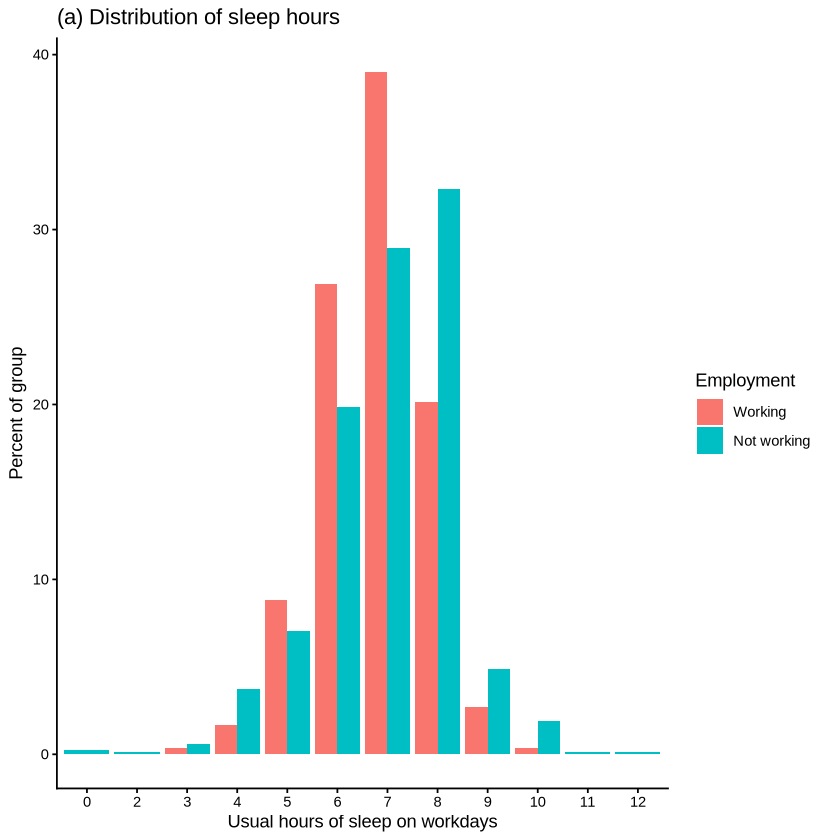

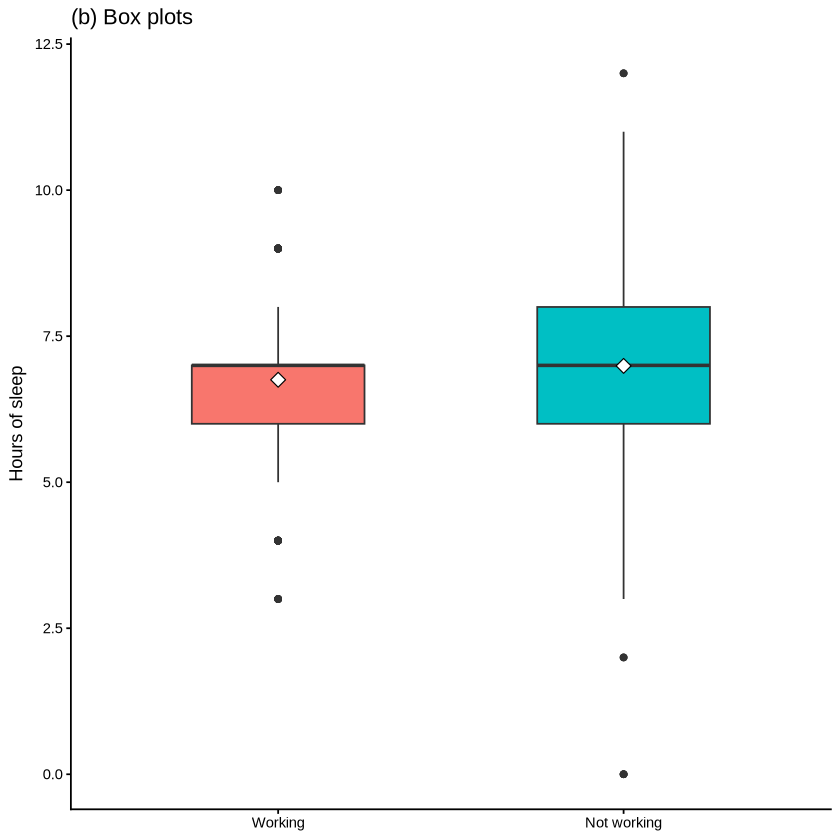

In [6]:
# ---- Appendix: R code for Introduction and EDA (Mia) ----
library(readr)
library(tidyverse)

MIDUS <- read_tsv("04652-0001-Data.tsv")

# Key variables
# B1PB3A  : currently working (1 = yes, 2 = no; 7 = don't know, 9 = inapplicable)
# B1SA57A : usual hours of sleep on workdays (-1 = inapplicable, 98 = don't know)
# B1PAGE_M2: age, B1PRSEX: sex (1 = male, 2 = female)
dat <- MIDUS |>
  select(M2ID, M2FAMNUM, B1PB3A, B1SA57A, B1PAGE_M2, B1PRSEX)

# ---- Data preparation: sample sizes at each step ----
n_all   <- nrow(dat)                                   # 4963
step1   <- dat |> filter(B1PB3A %in% c(1, 2))          # 4946
step2   <- step1 |> filter(!B1SA57A %in% c(-1, 98))    # 3972
c(all = n_all, employment_valid = nrow(step1), analysis = nrow(step2))
step1 |> count(B1SA57A %in% c(-1), B1SA57A == 98)      # 920 coded -1, 54 coded 98
n_distinct(dat$M2FAMNUM)                               # 3645 family IDs

# Compare respondents who were removed and kept in step 2
step1 |>
  mutate(removed = B1SA57A %in% c(-1, 98)) |>
  group_by(removed) |>
  summarise(n = n(), mean_age = mean(B1PAGE_M2))

sleep <- step2 |>
  mutate(Employment = factor(B1PB3A, levels = c(1, 2),
                             labels = c("Working", "Not working")),
         Sleep_hours = B1SA57A)

# ---- Table 1: summary statistics by group ----
sleep |>
  group_by(Employment) |>
  summarise(n = n(),
            mean = mean(Sleep_hours), sd = sd(Sleep_hours),
            median = median(Sleep_hours),
            q1 = quantile(Sleep_hours, 0.25), q3 = quantile(Sleep_hours, 0.75),
            min = min(Sleep_hours), max = max(Sleep_hours),
            pct_4_or_fewer = 100 * mean(Sleep_hours <= 4),
            pct_9_or_more  = 100 * mean(Sleep_hours >= 9),
            mean_age = mean(B1PAGE_M2), sd_age = sd(B1PAGE_M2),
            pct_female = 100 * mean(B1PRSEX == 2))

# Difference in means
means <- tapply(sleep$Sleep_hours, sleep$Employment, mean)
means["Working"] - means["Not working"]

# Percent of each group at each sleep duration
sleep |> count(Employment, Sleep_hours) |>
  group_by(Employment) |> mutate(pct = 100 * n / sum(n))

# ---- Figure 1(a): distribution of sleep hours by group ----
props <- sleep |>
  count(Employment, Sleep_hours) |>
  group_by(Employment) |>
  mutate(pct = 100 * n / sum(n))

ggplot(props, aes(x = factor(Sleep_hours), y = pct, fill = Employment)) +
  geom_col(position = "dodge") +
  labs(x = "Usual hours of sleep on workdays", y = "Percent of group",
       title = "(a) Distribution of sleep hours") +
  theme_classic()

# ---- Figure 1(b): box plots with mean ----
ggplot(sleep, aes(x = Employment, y = Sleep_hours, fill = Employment)) +
  geom_boxplot(width = 0.5) +
  stat_summary(fun = mean, geom = "point", shape = 23, fill = "white", size = 3) +
  labs(x = NULL, y = "Hours of sleep", title = "(b) Box plots") +
  theme_classic() + theme(legend.position = "none")